# 03 - RF-DETR Model, Training, and Optimization

This notebook covers Sections 2 and 3 of the project: the model, the training loop, hyperparameter experiments, early stopping, and checkpointing.

**Run order:** notebook 02 (cleaning) first, then this one, then notebook 04 (evaluation). Use a **GPU runtime** (Runtime > Change runtime type > T4 GPU).

**What we actually ran**

- **Model:** RF-DETR **Nano** (384 px input), fine-tuned from the COCO-pretrained weights on the cleaned 6-class dataset.
- **Training:** 10 epochs per run, early-stopping patience 3, batch size 8 with gradient accumulation 2 (effective batch 16), learning rate 1e-4 (decoder) and 1.5e-4 (backbone), on a Colab T4 GPU.
- **Experiments:** three runs: A (no augmentation), B (augmentation), C (augmentation plus cosine learning-rate schedule). The optional run D was not run.
- **How we got here:** the first attempt used the larger Small model for 20 epochs. It was taking too long, so we stopped it, switched to Nano, and cut the epochs to 10 and the early-stopping patience to 3 to save time.

**What is in here**

1. Setup, GPU check, and dataset restore
2. Model architecture, mapped onto the components in the assignment
3. A small from-scratch Hungarian matcher and loss, checked against the library's matcher
4. Preprocessing and augmentation
5. Three training experiments (the hyperparameter comparison)
6. Training curves and the comparison table
7. Results and observations

## 1. Setup

In [4]:
!pip install -q "rfdetr[train,augment]" tensorboard

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.7/604.7 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.7/102.7 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 406.3/406.3 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.7/409.7 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 678.2/678.2 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 788.9/788.9 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/

If pip prints a message asking you to restart the runtime, do that (Runtime > Restart session) and run the notebook again from the top.

In [5]:
import os, json, glob, time, shutil, zipfile, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

HAS_GPU = torch.cuda.is_available()
# A GPU is only needed for the training cells. Inspection, the matcher checks, curves and analysis run on CPU.
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (CPU runtime: do not run the training cells)", "| torch", torch.__version__)

from google.colab import drive
drive.mount("/content/drive")

# ---------- CONFIG ----------
PROJECT_DIR = "/content/drive/MyDrive/rf-detr-trash"   # checkpoints and results live here, so they survive a runtime reset
DATA_DIR    = "/content/trash-clean"                    # cleaned dataset produced by notebook 02
RUNS_DIR    = f"{PROJECT_DIR}/runs"
os.makedirs(RUNS_DIR, exist_ok=True)

GPU: none (CPU runtime: do not run the training cells) | torch 2.11.0+cpu
Mounted at /content/drive


### Dataset: restore it and check it

Notebook 02 writes the cleaned dataset to `/content/trash-clean`. Colab wipes `/content` when the runtime resets, so a zip copy is kept on Drive and restored here if needed.

In [6]:
ZIP_PATH = f"{PROJECT_DIR}/trash-clean.zip"

if not os.path.exists(f"{DATA_DIR}/train/_annotations.coco.json"):
    if os.path.exists(ZIP_PATH):
        with zipfile.ZipFile(ZIP_PATH) as z:
            z.extractall(os.path.dirname(DATA_DIR))
        print("Restored dataset from", ZIP_PATH)
    else:
        raise FileNotFoundError("Cleaned dataset not found. Run notebook 02 first (it creates /content/trash-clean).")

stats = {}
for s in ["train", "valid", "test"]:
    d = json.load(open(f"{DATA_DIR}/{s}/_annotations.coco.json"))
    ids = [c["id"] for c in d["categories"]]
    assert ids == list(range(len(ids))), f"{s}: category ids are not 0..K-1. Re-run notebook 02."
    stats[s] = (len(d["images"]), len(d["annotations"]))
CLASS_NAMES = [c["name"] for c in d["categories"]]
print("Classes:", CLASS_NAMES)
print("(images, boxes):", stats)

# Keep a copy on Drive for the next session
if not os.path.exists(ZIP_PATH):
    shutil.make_archive(ZIP_PATH[:-4], "zip", root_dir=os.path.dirname(DATA_DIR), base_dir=os.path.basename(DATA_DIR))
    print("Saved a zip copy of the dataset to", ZIP_PATH)

Restored dataset from /content/drive/MyDrive/rf-detr-trash/trash-clean.zip
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
(images, boxes): {'train': (1763, 1773), 'valid': (379, 383), 'test': (377, 382)}


## 2. The model: RF-DETR and how it maps to the assignment

**A note on the name.** The assignment describes RF-DETR as "Receptive Field Enhanced DETR". The model in the `rfdetr` library, which this project uses, is Roboflow's **RF-DETR**, a *real-time* detection transformer (paper: "RF-DETR: Neural Architecture Search for Real-Time Detection Transformers", Robinson et al., 2025). It has no module literally named "Receptive Field Enhancement Module", so we describe the model as it actually is. The table maps the assignment's list of components onto the real architecture.

| Assignment component | What RF-DETR actually has |
|---|---|
| CNN backbone (e.g. ResNet) | A **DINOv2 vision transformer** backbone with windowed attention (a ViT, not a CNN), pretrained on large image data |
| Receptive-field / feature enhancement | A **multi-scale projector** that turns backbone features into the decoder's input. The windowed-plus-global attention in the backbone is what widens the receptive field cheaply. Closest equivalent to the assignment's module, but not a separately named block |
| Transformer encoder-decoder | A **decoder-only** transformer (self-attention plus deformable cross-attention) with a two-stage query-selection step. The ViT backbone plays the encoder role. The Nano model we trained has **2 decoder layers** |
| Prediction heads (FFNs) | `class_embed` (linear layer for class scores) and `bbox_embed` (small MLP for box coordinates) |
| Hungarian matcher | `rfdetr.models.matcher.HungarianMatcher` |
| Classification + L1 + GIoU losses | `rfdetr.models.criterion.SetCriterion` (IoU-aware binary cross-entropy for classes, L1 and GIoU for boxes) |
| Optimizer | AdamW, with separate learning rates for backbone and the rest |

**Which variant was trained.** The model we trained is **RF-DETR Nano**: the same DINOv2-small windowed backbone and projector design, a 384 px input, 2 decoder layers, 300 queries, and about 30.5 million parameters (counted with the 91-class COCO head, before it is replaced by a 6-class head).

**Note on the printout below.** The inspection cell below loads the Nano variant (the one we trained). The count of about 30.5 million parameters is for the 91-class COCO head, before it is replaced by our 6-class head.

**Implementation strategy:** this is the "adaptation" route the assignment recommends. We fine-tune the open-source RF-DETR implementation, starting from its COCO-pretrained weights, on our 6-class dataset. Section 3 below adds our own small implementation of the matcher and loss so that part is demonstrated in code.

In [7]:
from rfdetr import RFDETRSmall, RFDETRNano, RFDETRMedium

MODEL_CLASS = RFDETRNano      # the variant we trained (384 px). RFDETRSmall (512 px) was tried first and dropped because it was too slow.

probe = MODEL_CLASS(pretrain_weights=None)       # architecture only, no weight download, used just for inspection
cfg = probe.model_config
print(f"Variant: {MODEL_CLASS.__name__}")
for k in ["encoder", "resolution", "patch_size", "num_windows", "hidden_dim", "dec_layers", "num_queries",
          "projector_scale", "two_stage", "group_detr", "num_select"]:
    print(f"  {k:16s} {getattr(cfg, k, 'n/a')}")

net = probe.model.model
print(f"\nTotal parameters: {sum(p.numel() for p in net.parameters())/1e6:.1f} M (head sized for 91 COCO classes here; ours is 6)")
print("\nTop-level modules and parameter counts:")
for name, child in net.named_children():
    print(f"  {name:14s} {type(child).__name__:20s} {sum(p.numel() for p in child.parameters())/1e6:7.2f} M")

bb = net.backbone[0]
print("\nBackbone:")
for name, child in bb.named_children():
    print(f"  {name:10s} {type(child).__name__:22s} {sum(p.numel() for p in child.parameters())/1e6:7.2f} M")
print("\nDecoder layers:", len(net.transformer.decoder.layers), "->",
      [n for n, _ in net.transformer.decoder.layers[0].named_children() if "attn" in n])

/usr/local/lib/python3.13/dist-packages/pydantic/main.py:263: PretrainWeightsCompatibilityWarning: RFDETRNanoConfig was instantiated with pretrain_weights=None. The model will be initialised from scratch, which typically produces lower accuracy than fine-tuning from the published checkpoint ('rf-detr-nano.pth').
  validated_self = self.__pydantic_validator__.validate_python(data, self_instance=self)
[2026-10-14 23:26:00] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-14 23:26:00] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


Variant: RFDETRNano
  encoder          dinov2_windowed_small
  resolution       384
  patch_size       16
  num_windows      2
  hidden_dim       256
  dec_layers       2
  num_queries      300
  projector_scale  ['P4']
  two_stage        True
  group_detr       13
  num_select       300

Total parameters: 30.5 M (head sized for 91 COCO classes here; ours is 6)

Top-level modules and parameter counts:
  transformer    Transformer             6.03 M
  class_embed    Linear                  0.02 M
  bbox_embed     MLP                     0.13 M
  refpoint_embed Embedding               0.02 M
  query_feat     Embedding               1.00 M
  backbone       Joiner                 23.27 M

Backbone:
  encoder    DinoV2                   21.82 M
  projector  MultiScaleProjector       1.44 M

Decoder layers: 2 -> ['self_attn', 'cross_attn']


In [8]:
# The real implementation of the matcher and the loss lives in the library. These headers are worth a screenshot for the report.
from rfdetr.models.matcher import HungarianMatcher
from rfdetr.models.criterion import SetCriterion
print(inspect.getdoc(HungarianMatcher))
init_doc = inspect.getdoc(HungarianMatcher.__init__) or ""
print("\nMatcher arguments:\n" + init_doc.split("use_pos_only")[0].strip())
print("\nLoss class:\n" + (inspect.getdoc(SetCriterion) or "").split("Parameters")[0].strip())

This class computes an assignment between the targets and the predictions of the network For efficiency reasons,
the targets don't include the no_object.

Because of this, in general, there are more predictions than targets. In this case, we do a 1-to-1 matching of the
best predictions, while the others are un-matched (and thus treated as non-objects).

Note:
    The focal loss exponent ``gamma`` is fixed at ``_FOCAL_LOSS_GAMMA`` (2.0) and is not
    configurable. Only ``focal_alpha`` can be adjusted at construction time.

Matcher arguments:
Creates the matcher.

Args:
    cost_class: Relative weight of the classification error in the matching cost.
    cost_bbox: Relative weight of the L1 error of the bounding box coordinates.
    cost_giou: Relative weight of the GIoU loss of the bounding box.
    focal_alpha: Alpha parameter for focal loss used in the classification cost.

Loss class:
This class computes the loss for Conditional DETR.

The process happens in two steps:
1) we compute

## 3. Hungarian matcher and loss, implemented from scratch

DETR-style models predict a fixed set of boxes (queries) and have no anchor boxes or non-maximum suppression. During training each ground-truth box must be paired with exactly one query. The **Hungarian algorithm** finds the pairing with the lowest total cost, where the cost mixes class error, L1 box distance, and (negative) generalized IoU. The loss is then computed only on those pairs, and unmatched queries are pushed towards "no object".

The code below is a compact version of that idea, with the same default weights as RF-DETR (class 2, L1 5, GIoU 2 for matching; class 1, L1 5, GIoU 2 for the loss). It is for explanation and testing. The actual training in Section 5 uses the library's optimized implementation.

In [9]:
import torch
import torch.nn.functional as F
from scipy.optimize import linear_sum_assignment
from torchvision.ops import generalized_box_iou, box_convert


def to_xyxy(b):
    """Convert normalised (cx, cy, w, h) boxes to (x1, y1, x2, y2)."""
    return box_convert(b, in_fmt="cxcywh", out_fmt="xyxy")


class SimpleHungarianMatcher:
    """Minimal DETR-style matcher: finds the one-to-one assignment between predicted queries and
    ground-truth boxes that minimises  w_cls * class_cost + w_l1 * L1_cost + w_giou * GIoU_cost."""

    def __init__(self, cost_class=2.0, cost_bbox=5.0, cost_giou=2.0, alpha=0.25, gamma=2.0):
        self.cost_class, self.cost_bbox, self.cost_giou = cost_class, cost_bbox, cost_giou
        self.alpha, self.gamma = alpha, gamma

    @torch.no_grad()
    def __call__(self, pred_logits, pred_boxes, targets):
        B, Q, _ = pred_logits.shape
        prob = pred_logits.flatten(0, 1).sigmoid()                 # [B*Q, num_classes]
        out_box = pred_boxes.flatten(0, 1)                         # [B*Q, 4]
        tgt_ids = torch.cat([t["labels"] for t in targets])        # [total_targets]
        tgt_box = torch.cat([t["boxes"] for t in targets])         # [total_targets, 4]

        # 1) classification cost (focal-loss style: cheap if the right class has high probability)
        neg = (1 - self.alpha) * prob ** self.gamma * (-(1 - prob + 1e-8).log())
        pos = self.alpha * (1 - prob) ** self.gamma * (-(prob + 1e-8).log())
        cost_cls = pos[:, tgt_ids] - neg[:, tgt_ids]
        # 2) L1 distance between box parameters
        cost_l1 = torch.cdist(out_box, tgt_box, p=1)
        # 3) generalised IoU (higher overlap -> lower cost)
        cost_giou = -generalized_box_iou(to_xyxy(out_box), to_xyxy(tgt_box))

        cost = self.cost_bbox * cost_l1 + self.cost_class * cost_cls + self.cost_giou * cost_giou
        cost = cost.view(B, Q, -1).cpu()
        sizes = [len(t["boxes"]) for t in targets]
        out = []
        for i, c in enumerate(cost.split(sizes, dim=-1)):
            rows, cols = linear_sum_assignment(c[i])                # Hungarian algorithm
            out.append((torch.as_tensor(rows, dtype=torch.int64), torch.as_tensor(cols, dtype=torch.int64)))
        return out


def detection_loss(pred_logits, pred_boxes, targets, matches, w_cls=1.0, w_l1=5.0, w_giou=2.0, alpha=0.25, gamma=2.0):
    """Set-prediction loss = w_cls * focal classification + w_l1 * L1 + w_giou * (1 - GIoU),
    computed on the matched (query, target) pairs; unmatched queries are trained towards 'no object'."""
    B, Q, C = pred_logits.shape
    num_boxes = max(sum(len(t["labels"]) for t in targets), 1)

    # classification target: one-hot at matched queries, all zeros elsewhere
    cls_target = torch.zeros_like(pred_logits)
    for b, (qi, ti) in enumerate(matches):
        cls_target[b, qi, targets[b]["labels"][ti]] = 1.0
    p = pred_logits.sigmoid()
    ce = F.binary_cross_entropy_with_logits(pred_logits, cls_target, reduction="none")
    p_t = p * cls_target + (1 - p) * (1 - cls_target)
    focal = ce * (1 - p_t) ** gamma * (alpha * cls_target + (1 - alpha) * (1 - cls_target))
    loss_cls = focal.sum() / num_boxes

    # box losses on matched pairs only
    src = torch.cat([pred_boxes[b, qi] for b, (qi, _) in enumerate(matches)])
    tgt = torch.cat([targets[b]["boxes"][ti] for b, (_, ti) in enumerate(matches)])
    loss_l1 = F.l1_loss(src, tgt, reduction="none").sum() / num_boxes
    loss_giou = (1 - torch.diag(generalized_box_iou(to_xyxy(src), to_xyxy(tgt)))).sum() / num_boxes

    total = w_cls * loss_cls + w_l1 * loss_l1 + w_giou * loss_giou
    return dict(total=total, cls=loss_cls, l1=loss_l1, giou=loss_giou)

In [10]:
# Check 1: our matcher vs the library's matcher on 200 random cases. They should pick the same pairs.
torch.manual_seed(1)
lib_matcher = HungarianMatcher(cost_class=2.0, cost_bbox=5.0, cost_giou=2.0, focal_alpha=0.25)
my_matcher = SimpleHungarianMatcher()
agree, N = 0, 200
for _ in range(N):
    B, Q, C = 3, 25, 6
    logits = torch.randn(B, Q, C) * 2
    boxes = torch.rand(B, Q, 4) * 0.4 + 0.2
    targets = []
    for b in range(B):
        n = int(torch.randint(1, 4, (1,)))
        targets.append(dict(labels=torch.randint(0, C, (n,)), boxes=torch.rand(n, 4) * 0.4 + 0.2))
    a = my_matcher(logits, boxes, targets)
    l = lib_matcher({"pred_logits": logits, "pred_boxes": boxes}, targets)
    agree += all(sorted(zip(x[0].tolist(), x[1].tolist())) == sorted(zip(y[0].tolist(), y[1].tolist())) for x, y in zip(a, l))
print(f"Our matcher gives the same assignment as the library in {agree}/{N} random cases")

# Check 2: a perfect prediction gets ~zero loss, a wrong class is penalised
targets = [dict(labels=torch.tensor([2]), boxes=torch.tensor([[.5, .5, .4, .3]]))]
logits = torch.full((1, 10, 6), -8.0); boxes = torch.rand(1, 10, 4) * 0.3 + 0.1
logits[0, 4, 2] = 8.0; boxes[0, 4] = targets[0]["boxes"][0]
good = detection_loss(logits, boxes, targets, my_matcher(logits, boxes, targets))
bad_logits = logits.clone(); bad_logits[0, 4, 2] = -8.0; bad_logits[0, 4, 0] = 8.0
bad = detection_loss(bad_logits, boxes, targets, my_matcher(bad_logits, boxes, targets))
print("Perfect prediction loss:", {k: round(float(v), 4) for k, v in good.items()})
print("Wrong-class loss       :", {k: round(float(v), 4) for k, v in bad.items()})

Our matcher gives the same assignment as the library in 200/200 random cases
Perfect prediction loss: {'total': 0.0, 'cls': 0.0, 'l1': 0.0, 'giou': 0.0}
Wrong-class loss       : {'total': 7.995, 'cls': 7.995, 'l1': 0.0, 'giou': 0.0}


## 4. Preprocessing and augmentation

What happens to each image before the model sees it:

- **Resizing:** images are resized to the model's square input size, which is 384 x 384 pixels for the Nano model we trained. Our images are 512x384, so the width is reduced. Boxes are rescaled with the image.
- **Normalization:** pixel values are scaled to 0-1 and normalized with the ImageNet mean and standard deviation (0.485, 0.456, 0.406) and (0.229, 0.224, 0.225), which is what the DINOv2 backbone was trained with.
- **Multi-scale training:** the library varies the training resolution slightly between batches, which acts as extra augmentation.
- **Augmentation (our experiment):** the library's default applies only a horizontal flip. Run A turns augmentation off. Runs B and C use the custom set below: horizontal and vertical flips, rotation up to 20 degrees, and brightness and contrast changes. Flips and moderate rotations are reasonable for this dataset because the photos are taken from above, where any orientation is plausible. Brightness and contrast changes cover the lighting differences between photos. The rotation angle is kept small so boxes do not become much larger than the object.

In [11]:
AUG_CUSTOM = {
    "HorizontalFlip": {"p": 0.5},
    "VerticalFlip": {"p": 0.5},
    "Rotate": {"limit": 20, "p": 0.4},
    "RandomBrightnessContrast": {"brightness_limit": 0.2, "contrast_limit": 0.2, "p": 0.4},
}

## 5. Training experiments

Three runs, each changing one thing, so the effect of each optimization can be discussed in the report.

| Run | Augmentation | LR schedule | Purpose |
|---|---|---|---|
| `exp_a_baseline_noaug` | none | step decay (default) | Baseline |
| `exp_b_augmentation` | flips, rotation, brightness | step decay | Effect of augmentation |
| `exp_c_aug_cosine` | same as B | cosine with 1 warm-up epoch | Effect of the learning-rate schedule |

An optional fourth run (`exp_d_aug_lowlr`, half the learning rate) is defined but was **not run**.

**Settings used for all three runs**

- Model: RF-DETR Nano, starting from the COCO-pretrained weights
- 10 epochs, batch size 8 with gradient accumulation of 2 (effective batch 16), seed 42
- Learning rate 1e-4 for the decoder and 1.5e-4 for the backbone, AdamW, gradient clipping, exponential moving average (EMA) of the weights, mixed precision
- Validation loss logged every epoch (`compute_val_loss=True`)

**Training controls (assignment Section 3)**

- **Early stopping:** stops when validation mAP@0.5:0.95 has not improved by at least 0.001 for **3** epochs (reduced from 5 to save time). The library monitors validation *mAP* rather than validation *loss*, which is the usual choice for detection transformers because their loss is noisy. Validation loss is still logged each epoch, and Section 6 plots it next to mAP. Because the assignment asks for early stopping based on validation loss, Section 6 also replays each run's validation loss with a patience-3 rule to show when loss-based stopping would have triggered. In practice early stopping did not shorten any run: run C signaled a stop at epoch 10, which was also the last epoch.
- **Checkpointing:** a checkpoint is written every 5 epochs and the best weights are kept automatically (`checkpoint_best_total.pth`). Everything is saved to Drive, so a disconnect does not lose a run.
- **Reported mAP:** the best-checkpoint and the validation mAP in the logs come from the EMA weights. The regular (non-EMA) weights were not evaluated separately.

**Training time (measured on a Colab T4 with the Nano model, 10 epochs):** run A 17.6 minutes, run B 23.0 minutes, run C 24.5 minutes. The augmentation runs were slower, probably because the augmentation is applied on the CPU.

In [12]:
EPOCHS = 10   # reduced from 20 to save time
BASE = dict(
    dataset_dir=DATA_DIR,
    epochs=EPOCHS,
    batch_size=8, grad_accum_steps=2,        # effective batch size 16 (use 4 and 4 if out of memory)
    num_workers=2,
    lr=1e-4, lr_encoder=1.5e-4,
    early_stopping=True, early_stopping_patience=5, early_stopping_min_delta=0.001,
    checkpoint_interval=5,
    compute_val_loss=True,                   # also log validation loss every epoch
    tensorboard=True,
    seed=42,
)
BASE["early_stopping_patience"] = 3   # patience lowered from 5 to 3 so runs stop sooner
RUN_LIST = ["exp_a_baseline_noaug", "exp_b_augmentation"]   # first plan: only A and B (overridden at the bottom of this cell)
MODEL_CLASS = RFDETRNano   # switched from Small to the faster Nano model to save time

EXPERIMENTS = {
    "exp_a_baseline_noaug": dict(aug_config={}),
    "exp_b_augmentation":   dict(aug_config=AUG_CUSTOM),
    "exp_c_aug_cosine":     dict(aug_config=AUG_CUSTOM, lr_scheduler="cosine", warmup_epochs=1.0),
    "exp_d_aug_lowlr":      dict(aug_config=AUG_CUSTOM, lr=5e-5, lr_encoder=7.5e-5),   # optional
}

# Runs executed: A, B and C. Run D (lower learning rate) was not run.
RUN_LIST = ["exp_a_baseline_noaug", "exp_b_augmentation", "exp_c_aug_cosine"]

In [13]:
def latest_resume_checkpoint(out):
    # Newest Lightning checkpoint (checkpoint_<epoch>.ckpt or last.ckpt) in a run folder, or None

    cands = glob.glob(f"{out}/*.ckpt")
    return max(cands, key=os.path.getmtime) if cands else None


def run_experiment(name, force=False):   # force=True deletes the run's folder and retrains it from scratch; the default keeps finished runs
    out = f"{RUNS_DIR}/{name}"
    marker = f"{out}/experiment.json"            # written only when a run finishes (including early stopping)
    if os.path.exists(marker) and not force:
        print(f"[{name}] already finished, skipping (set force=True to retrain from scratch).")
        return
    assert HAS_GPU, "Training needs a GPU (Runtime > Change runtime type > T4 GPU)."
    if force and os.path.isdir(out):
        shutil.rmtree(out)
    cfg = {**BASE, **EXPERIMENTS[name], "output_dir": out}

    # An unfinished run (disconnect, timeout) picks up from its latest checkpoint
    ckpt = latest_resume_checkpoint(out)
    if ckpt:
        cfg["resume"] = ckpt
        print(f"[{name}] resuming from {ckpt}")

    print(f"\n===== {name} =====")
    print({k: v for k, v in cfg.items() if k not in ("dataset_dir",)})
    model = MODEL_CLASS()                      # downloads the COCO-pretrained weights on first use
    t0 = time.time()
    model.train(**cfg)
    minutes = (time.time() - t0) / 60
    with open(marker, "w") as f:
        json.dump(dict(name=name, train_minutes=round(minutes, 1), model=MODEL_CLASS.__name__,
                       config={k: v for k, v in cfg.items() if k != "resume"}), f, indent=2, default=str)
    print(f"[{name}] finished in {minutes:.1f} min")
    del model
    torch.cuda.empty_cache()

run_experiment(RUN_LIST[0])

[exp_a_baseline_noaug] already finished, skipping (set force=True to retrain from scratch).


Run the next experiments one cell at a time, so a problem in one run does not cost you the others.

In [ ]:
run_experiment(RUN_LIST[1])

Val (ema) (Epoch 10/10) — Overall Metrics            
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃           mAP            ┃  mAR   ┃         F1 sweep         ┃
┡━━━━━━━━┯━━━━━━━━┯━━━━━━━━╇━━━━━━━━╇━━━━━━━━┯━━━━━━━━┯━━━━━━━━┩
│ 50:95  │   50   │   75   │  @500  │   F1   │  Prec  │ Recall │
├────────┼────────┼────────┼────────┼────────┼────────┼────────┤
│ 0.9196 │ 0.9505 │ 0.9505 │ 0.9816 │ 0.9144 │ 0.9239 │ 0.9057 │
└────────┴────────┴────────┴────────┴────────┴────────┴────────┘

INFO:pytorch_lightning.callbacks.early_stopping:Metric __rfdetr_effective_map__ improved by 0.011 >= min_delta = 0.001. New best score: 0.920


[2026-10-14 16:05:20] [INFO] rf-detr - Best EMA metric improved to 0.9196 (epoch 9)


INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


[2026-10-14 16:06:58] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.9196)
[exp_b_augmentation] finished in 23.0 min


In [ ]:
run_experiment(RUN_LIST[2])

Val (ema) (Epoch 10/10) — Overall Metrics            
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃           mAP            ┃  mAR   ┃         F1 sweep         ┃
┡━━━━━━━━┯━━━━━━━━┯━━━━━━━━╇━━━━━━━━╇━━━━━━━━┯━━━━━━━━┯━━━━━━━━┩
│ 50:95  │   50   │   75   │  @500  │   F1   │  Prec  │ Recall │
├────────┼────────┼────────┼────────┼────────┼────────┼────────┤
│ 0.9167 │ 0.9453 │ 0.9439 │ 0.9812 │ 0.8972 │ 0.8984 │ 0.8969 │
└────────┴────────┴────────┴────────┴────────┴────────┴────────┘

INFO:pytorch_lightning.callbacks.early_stopping:Monitored metric __rfdetr_effective_map__ did not improve in the last 3 records. Best score: 0.917. Signaling Trainer to stop.
INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


[2026-10-14 16:31:29] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.9168)
[exp_c_aug_cosine] finished in 24.5 min


In [ ]:
# Optional fourth run (learning-rate sensitivity). Uncomment to run it.
# run_experiment("exp_d_aug_lowlr")

## 6. Training curves and comparison

Reads each run's `metrics.csv` and plots training loss, validation loss, and validation mAP per epoch. If the validation loss rises while mAP is still improving, that is normal for detection transformers, so explain it that way in the report rather than treating it as overfitting by itself.

Runs with metrics: ['exp_a_baseline_noaug', 'exp_b_augmentation', 'exp_c_aug_cosine']


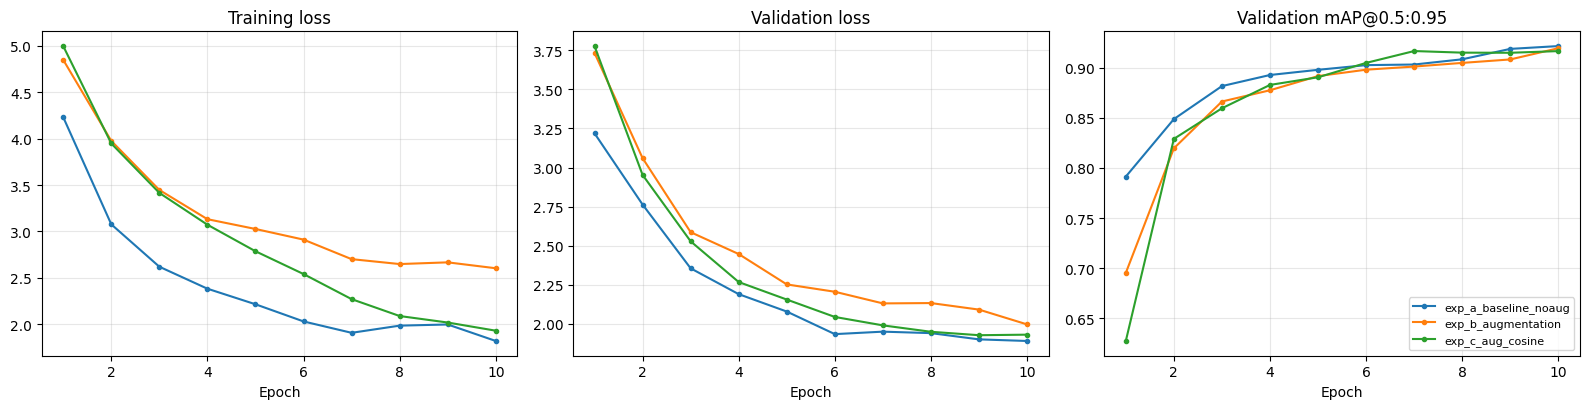

In [14]:
def load_metrics(name):
    paths = glob.glob(f"{RUNS_DIR}/{name}/**/metrics.csv", recursive=True)
    if not paths:
        return None
    df = pd.read_csv(paths[0])
    # Lightning writes separate rows for training steps and validation epochs. Average per epoch to get one row each.
    return df.groupby("epoch").mean(numeric_only=True)

def first_col(df, candidates):
    for c in candidates:
        if c in df.columns and df[c].notna().any():
            return c
    return None

done = [n for n in EXPERIMENTS if load_metrics(n) is not None]
print("Runs with metrics:", done)

COLORS = plt.cm.tab10.colors
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for i, n in enumerate(done):
    ep = load_metrics(n)
    for ax, cands, title in [
        (axes[0], ["train/loss"], "Training loss"),
        (axes[1], ["val/loss"], "Validation loss"),
        (axes[2], ["val/ema_mAP_50_95", "val/mAP_50_95"], "Validation mAP@0.5:0.95"),
    ]:
        col = first_col(ep, cands)
        if col is not None:
            ax.plot(ep.index + 1, ep[col], marker="o", ms=3, color=COLORS[i], label=n)
        ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(alpha=.3)
axes[2].legend(fontsize=8)
plt.tight_layout()
os.makedirs(f"{PROJECT_DIR}/results", exist_ok=True)
plt.savefig(f"{PROJECT_DIR}/results/training_curves.png", dpi=170, bbox_inches="tight")
plt.show()

In [15]:
if not done:
    raise SystemExit("No finished runs yet. Run at least one experiment cell in Section 5 first.")

rows = []
for n in done:
    ep = load_metrics(n)
    mcol = first_col(ep, ["val/ema_mAP_50_95", "val/mAP_50_95"])
    m50 = first_col(ep, ["val/ema_mAP_50", "val/mAP_50"])
    vcol = first_col(ep, ["val/loss"])
    info = {}
    p = f"{RUNS_DIR}/{n}/experiment.json"
    if os.path.exists(p):
        info = json.load(open(p))
    best_ep = int(ep[mcol].idxmax()) if mcol else None
    rows.append(dict(
        run=n, epochs_run=len(ep),
        best_val_mAP_50_95=round(float(ep[mcol].max()), 4) if mcol else None,
        val_mAP_50_at_best=round(float(ep.loc[best_ep, m50]), 4) if (m50 and best_ep is not None) else None,
        best_epoch=best_ep + 1 if best_ep is not None else None,
        final_val_loss=round(float(ep[vcol].dropna().iloc[-1]), 4) if vcol else None,
        train_minutes=info.get("train_minutes"),
    ))
comparison = pd.DataFrame(rows).sort_values("best_val_mAP_50_95", ascending=False)
display(comparison)
comparison.to_csv(f"{PROJECT_DIR}/results/experiment_comparison.csv", index=False)

best_run = comparison.iloc[0]["run"]
open(f"{PROJECT_DIR}/results/best_run.txt", "w").write(best_run)
print(f"\nBest run on the VALIDATION set: {best_run}")
print(f"Set RUN_NAME = \"{best_run}\" in notebook 04 to evaluate it on the test set.")

,run,epochs_run,best_val_mAP_50_95,val_mAP_50_at_best,best_epoch,final_val_loss,train_minutes
0,exp_a_baseline_noaug,10,0.9218,0.9457,10,1.8900,17.6
1,exp_b_augmentation,10,0.9196,0.9505,10,1.9961,23.0
2,exp_c_aug_cosine,10,0.9168,0.9445,7,1.9304,24.5



Best run on the VALIDATION set: exp_a_baseline_noaug
Set RUN_NAME = "exp_a_baseline_noaug" in notebook 04 to evaluate it on the test set.


### Early stopping on validation loss (replay)

The training library stops on validation mAP (see Section 5), so we did not retrain with a loss-based rule. The assignment asks for early stopping on validation loss, so this cell replays each run's logged validation loss with that rule: stop when the loss has not improved for `PATIENCE` epochs. It reads only the saved `metrics.csv` files, so it needs no GPU and no retraining.

It answers two questions. Would loss-based stopping have ended a run earlier than the 10 epochs? And does the epoch with the lowest validation loss agree with the epoch with the best validation mAP?

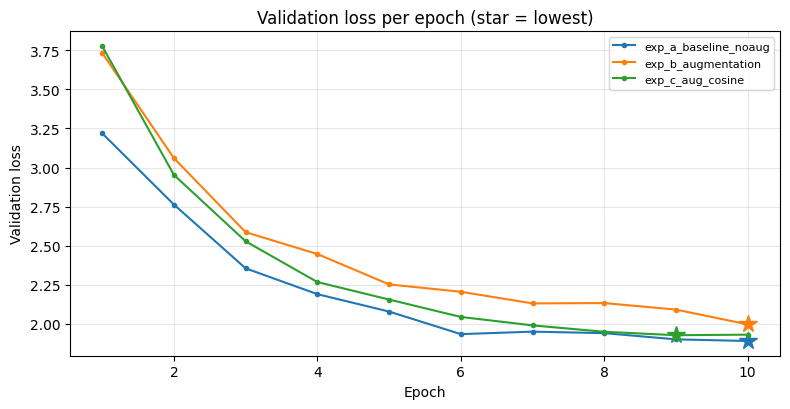

,run,epochs_run,lowest_val_loss,epoch_of_lowest_loss,loss_rule_would_stop_at,epoch_of_best_mAP
0,exp_a_baseline_noaug,10,1.8900,10,never,10
1,exp_b_augmentation,10,1.9961,10,never,10
2,exp_c_aug_cosine,10,1.9269,9,never,7


If epoch_of_lowest_loss differs from epoch_of_best_mAP, the two criteria disagree. State this in the report.


In [16]:
PATIENCE  = 3        # same patience as the mAP-based rule used in training
MIN_DELTA = 0.0      # loss must drop by more than this to count as an improvement

rows = []
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, n in enumerate(done):
    ep = load_metrics(n)
    vcol = first_col(ep, ["val/loss"])
    mcol = first_col(ep, ["val/ema_mAP_50_95", "val/mAP_50_95"])
    if vcol is None:
        print(f"{n}: no validation loss logged, skipped"); continue
    loss = ep[vcol].dropna()
    best, best_i, since, stop_at = float("inf"), None, 0, None
    for k, (e, v) in enumerate(loss.items(), start=1):
        if v < best - MIN_DELTA:
            best, best_i, since = v, k, 0
        else:
            since += 1
            if since >= PATIENCE and stop_at is None:
                stop_at = k
    rows.append(dict(run=n, epochs_run=len(loss), lowest_val_loss=round(best, 4), epoch_of_lowest_loss=best_i,
                     loss_rule_would_stop_at=stop_at if stop_at else "never",
                     epoch_of_best_mAP=int(ep[mcol].idxmax()) + 1 if mcol else None))
    ax.plot(loss.index + 1, loss.values, marker="o", ms=3, color=COLORS[i], label=n)
    ax.plot(best_i, best, marker="*", ms=13, color=COLORS[i])
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation loss"); ax.grid(alpha=.3)
ax.set_title("Validation loss per epoch (star = lowest)"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/results/val_loss_early_stopping.png", dpi=170, bbox_inches="tight")
plt.show()

es = pd.DataFrame(rows)
display(es)
es.to_csv(f"{PROJECT_DIR}/results/val_loss_early_stopping.csv", index=False)
print("If epoch_of_lowest_loss differs from epoch_of_best_mAP, the two criteria disagree. State this in the report.")

**Reading the replay.** Report the table as it comes out: when the loss rule would have stopped each run (or `never`), and whether the lowest-loss epoch matches the best-mAP epoch. If they differ, say that validation loss and detection quality do not move together exactly, which is why the library monitors mAP.

### 7. Results and observations

Validation results for the three runs (Nano, 10 epochs, EMA weights). The test set was not used here.

| Run | Best val mAP@0.5:0.95 | Val mAP@0.5 at best | Best epoch | Final val loss | Minutes |
|---|---|---|---|---|---|
| A: no augmentation | 0.9218 | 0.9457 | 10 | 1.8900 | 17.6 |
| B: augmentation | 0.9196 | 0.9505 | 10 | 1.9961 | 23.0 |
| C: augmentation + cosine | 0.9168 | 0.9445 | 7 | 1.9304 | 24.5 |

**Effect of augmentation (A vs B).** The two runs are essentially tied. The no-augmentation baseline had the slightly higher mAP@0.5:0.95 (0.9218 against 0.9196), while the augmented run had the slightly higher mAP@0.5 (0.9505 against 0.9457). Each configuration was trained once with one seed, so a gap this small should not be read as a real effect. Augmentation gave no measurable improvement here and added about five minutes of training time. A likely reason, which we have not tested, is that the dataset is easy (one object per image on a plain background) and the pretrained model already performs well, so there is little for augmentation to fix.

**Effect of the learning-rate schedule (B vs C).** The cosine schedule with one warm-up epoch did not beat step decay: 0.9168 against 0.9196. Its best epoch was 7, while runs A and B were still at their best at epoch 10.

**Early stopping and training length.** Early stopping with patience 3 did not shorten any run. Because A and B reached their best score at the final epoch, they were probably still improving when the 10-epoch limit ended training, so longer training might have helped slightly. We limited the runs to 10 epochs to save time.

**Validation loss.** The final validation losses were 1.8900 (A), 1.9961 (B) and 1.9304 (C). Run B has a higher validation loss than A even though its mAP is similar, so the two measures do not move together exactly. This is consistent with the loss of detection transformers being noisy, which is why mAP is used for early stopping and model selection.

**Model selection.** The final model was chosen on **validation** performance only. By the rule "highest validation mAP@0.5:0.95", run A (`exp_a_baseline_noaug`) is selected, although its margin over B is within noise. The test set is used once, in notebook 04, with `RUN_NAME = "exp_a_baseline_noaug"`.

**Limitations of these experiments.** The smaller Nano model was used for speed, each run was trained for only 10 epochs, each configuration was run once with a single seed, and only three configurations were compared.